In [2]:
import pandas as pd

data_df = pd.read_csv("C:/Users/hemanathan/OneDrive/Desktop/guvi hcl/Mobile review/Mobile Reviews Sentiment null.csv")

In [3]:
data_df.isnull().sum()


review_id                  0
customer_name              0
age                        0
brand                      0
model                      0
price_usd               2450
price_local             2431
currency                   0
exchange_rate_to_usd       0
rating                  2453
sentiment               2445
country                    0
language                   0
review_date                0
verified_purchase          0
battery_life_rating        0
camera_rating              0
performance_rating         0
design_rating              0
display_rating             0
helpful_votes              0
source                  2448
dtype: int64

In [4]:
print(data_df.columns)
print(data_df.shape)

Index(['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd',
       'price_local', 'currency', 'exchange_rate_to_usd', 'rating',
       'sentiment', 'country', 'language', 'review_date', 'verified_purchase',
       'battery_life_rating', 'camera_rating', 'performance_rating',
       'design_rating', 'display_rating', 'helpful_votes', 'source'],
      dtype='str')
(50000, 22)


In [5]:
data_df.duplicated().sum()

np.int64(0)

In [6]:
# Strip extra spaces from column names, then drop Campaign_ID and Date
data_df.columns = data_df.columns.str.strip()
data_df = data_df.drop(columns=['customer_name', 'review_date'], errors='ignore')

In [7]:
data_df.info

<bound method DataFrame.info of        review_id  age     brand            model  price_usd price_local  \
0              1   45    Realme    Realme 12 Pro     337.31   ₹27996.73   
1              2   18    Realme    Realme 12 Pro     307.78   R$1754.35   
2              3   27    Google          Pixel 6     864.53   ₹71755.99   
3              4   19    Xiaomi    Redmi Note 13     660.94  د.إ2425.65   
4              5   38  Motorola          Edge 50     792.13   R$4515.14   
...          ...  ...       ...              ...        ...         ...   
49995      49996   18    Realme    Realme 12 Pro     526.10    A$804.93   
49996      49997   28   Samsung   Galaxy Note 20     911.85   A$1395.13   
49997      49998   21     Apple        iPhone SE    1155.32  د.إ4240.02   
49998      49999   31    Realme  Realme Narzo 70     459.04         NaN   
49999      50000   44  Motorola     Moto G Power     380.16    $380.16    

      currency  exchange_rate_to_usd  rating sentiment    country  

In [8]:
data_df.dtypes

review_id                 int64
age                       int64
brand                       str
model                       str
price_usd               float64
price_local                 str
currency                    str
exchange_rate_to_usd    float64
rating                  float64
sentiment                   str
country                     str
language                    str
verified_purchase          bool
battery_life_rating       int64
camera_rating             int64
performance_rating        int64
design_rating             int64
display_rating            int64
helpful_votes             int64
source                      str
dtype: object

In [9]:
import pandas as pd

# Clean and convert columns to numeric (removes symbols/letters and forces conversion)
for col in ['price_local']:
    if col in data_df.columns:
        # Remove anything that isn't a digit or a decimal point
        data_df[col] = data_df[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
        # Convert to float, turning empty or invalid strings into NaN
        data_df[col] = pd.to_numeric(data_df[col], errors='coerce')

print("Data types successfully converted to numeric!")

Data types successfully converted to numeric!


In [10]:
# 1. Correct the formula across the entire dataset (Dividing local price by the exchange rate)
data_df['price_usd'] = data_df['price_local'] / data_df['exchange_rate_to_usd']

# 2. Check the summary statistics of price_usd to verify it's normal now
print(data_df['price_usd'].describe())

# 3. Check those same problematic rows to make sure they look realistic
sample_check = data_df[data_df['model'].isin(['Galaxy A55', 'Pixel 8', 'Mi 13 Pro', 'iPhone 15 Pro'])]
print(sample_check[['brand', 'model', 'price_usd', 'price_local', 'exchange_rate_to_usd']])

count    41623.000000
mean       690.154412
std        310.507052
min        180.020000
25%        451.385088
50%        637.679739
75%        901.595875
max       1499.884615
Name: price_usd, dtype: float64
         brand          model    price_usd  price_local  exchange_rate_to_usd
11      Xiaomi      Mi 13 Pro   495.449275       683.72                  1.38
24       Apple  iPhone 15 Pro   997.610000       997.61                  1.00
25      Google        Pixel 8   506.505376       471.05                  0.93
34     Samsung     Galaxy A55  1071.572464      1478.77                  1.38
41      Google        Pixel 8   887.550725      1224.82                  1.38
...        ...            ...          ...          ...                   ...
49974   Xiaomi      Mi 13 Pro   449.959649      2564.77                  5.70
49983  Samsung     Galaxy A55   948.741935       882.33                  0.93
49986    Apple  iPhone 15 Pro  1408.568627      2155.11                  1.53
49991   Goog

In [11]:
data_df.isnull().sum()

review_id                  0
age                        0
brand                      0
model                      0
price_usd               8377
price_local             8377
currency                   0
exchange_rate_to_usd       0
rating                  2453
sentiment               2445
country                    0
language                   0
verified_purchase          0
battery_life_rating        0
camera_rating              0
performance_rating         0
design_rating              0
display_rating             0
helpful_votes              0
source                  2448
dtype: int64

In [12]:
# 1. Fill remaining numerical nulls with the median
# remaining null values after the calculation and other numerical data
data_df['price_usd'] = data_df['price_usd'].fillna(data_df['price_usd'].median())
data_df['price_local'] = data_df['price_local'].fillna(data_df['price_local'].median())
data_df['rating'] = data_df['rating'].fillna(data_df['rating'].median())

In [13]:
data_df.duplicated().sum()

# Counts total duplicate rows
print("Number of duplicate rows:", data_df.duplicated().sum())

Number of duplicate rows: 0


In [14]:
#  Fill remaining categorical nulls with 'Unknown'

data_df['sentiment'] = data_df['sentiment'].fillna('Unknown')
data_df['source'] = data_df['source'].fillna('Unknown')

In [15]:
data_df.isnull().sum()

review_id               0
age                     0
brand                   0
model                   0
price_usd               0
price_local             0
currency                0
exchange_rate_to_usd    0
rating                  0
sentiment               0
country                 0
language                0
verified_purchase       0
battery_life_rating     0
camera_rating           0
performance_rating      0
design_rating           0
display_rating          0
helpful_votes           0
source                  0
dtype: int64

In [16]:
data_df = data_df.drop(columns=['review_id ', 'age','source'], errors='ignore')

In [17]:
# Verify the final clean columns list
print("Final columns in data_df:", data_df.columns.tolist())

Final columns in data_df: ['review_id', 'brand', 'model', 'price_usd', 'price_local', 'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country', 'language', 'verified_purchase', 'battery_life_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating', 'helpful_votes']


In [18]:
# Save your current cleaned DataFrame
data_df.to_csv("cleaned_smartphones.csv", index=False)
print("DataFrame successfully saved as 'cleaned_smartphones.csv'!")

DataFrame successfully saved as 'cleaned_smartphones.csv'!


C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\87668279.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.index, y=top_brands.values, palette="Blues_r")


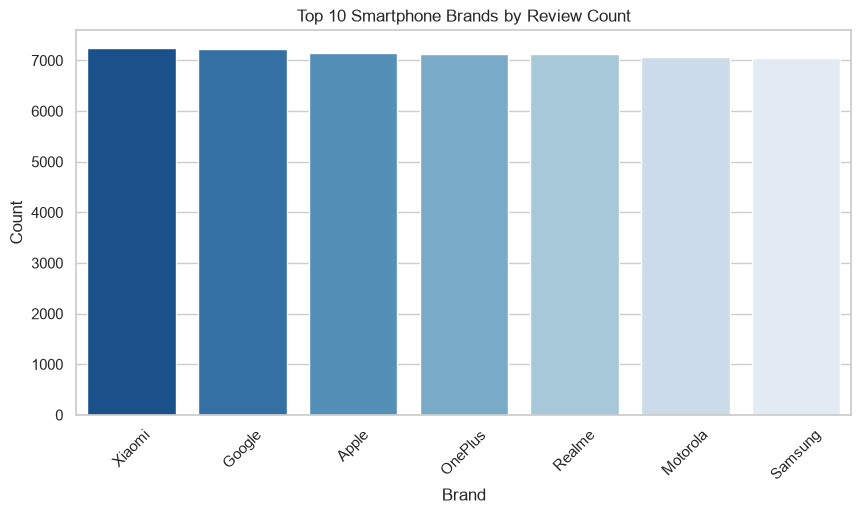

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# 1. Brand Bar Chart (Top 10 Brands)
plt.figure(figsize=(10, 5))
top_brands = data_df['brand'].value_counts().head(10)
sns.barplot(x=top_brands.index, y=top_brands.values, palette="Blues_r")
plt.title("Top 10 Smartphone Brands by Review Count")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\632313889.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette="Blues_r")


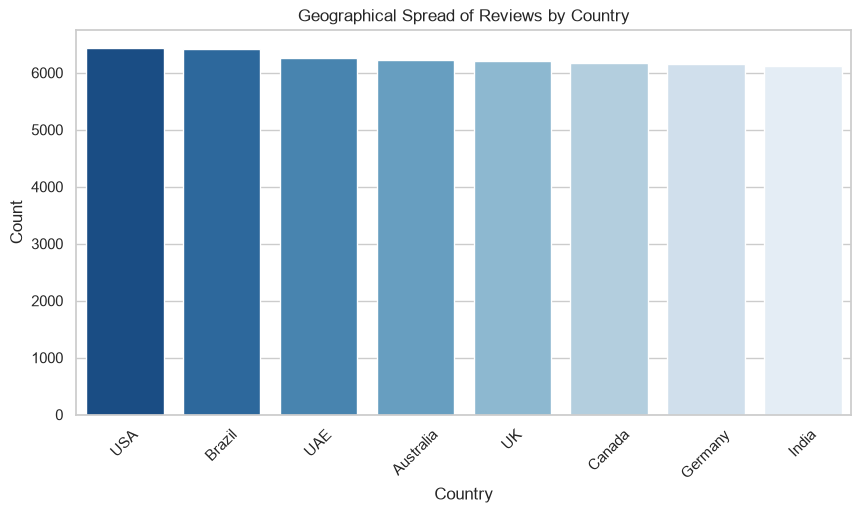

In [20]:
# 2. Country Bar Chart (Geographical Spread)
plt.figure(figsize=(10, 5))
top_countries = data_df['country'].value_counts().head(10)
sns.barplot(x=top_countries.index, y=top_countries.values, palette="Blues_r")
plt.title("Geographical Spread of Reviews by Country")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

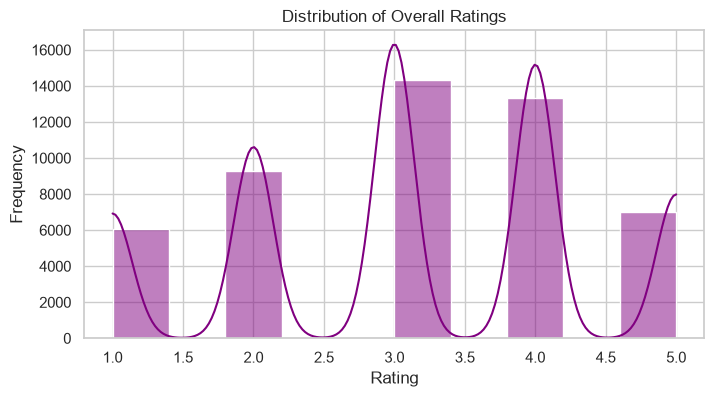

In [21]:
# 3. Rating Histogram
plt.figure(figsize=(8, 4))
sns.histplot(data_df['rating'], bins=10, kde=True, color="purple")
plt.title("Distribution of Overall Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

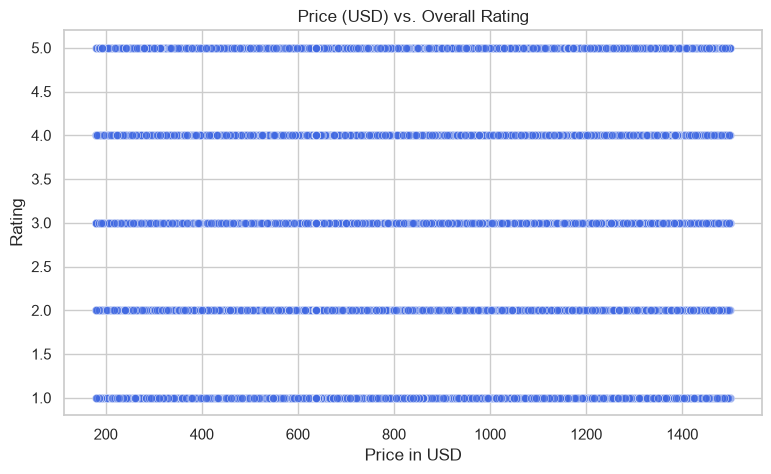

In [22]:
# 4. Price vs. Rating Scatter Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data_df, x='price_usd', y='rating', alpha=0.6, color="royalblue")
plt.title("Price (USD) vs. Overall Rating")
plt.xlabel("Price in USD")
plt.ylabel("Rating")
plt.show()

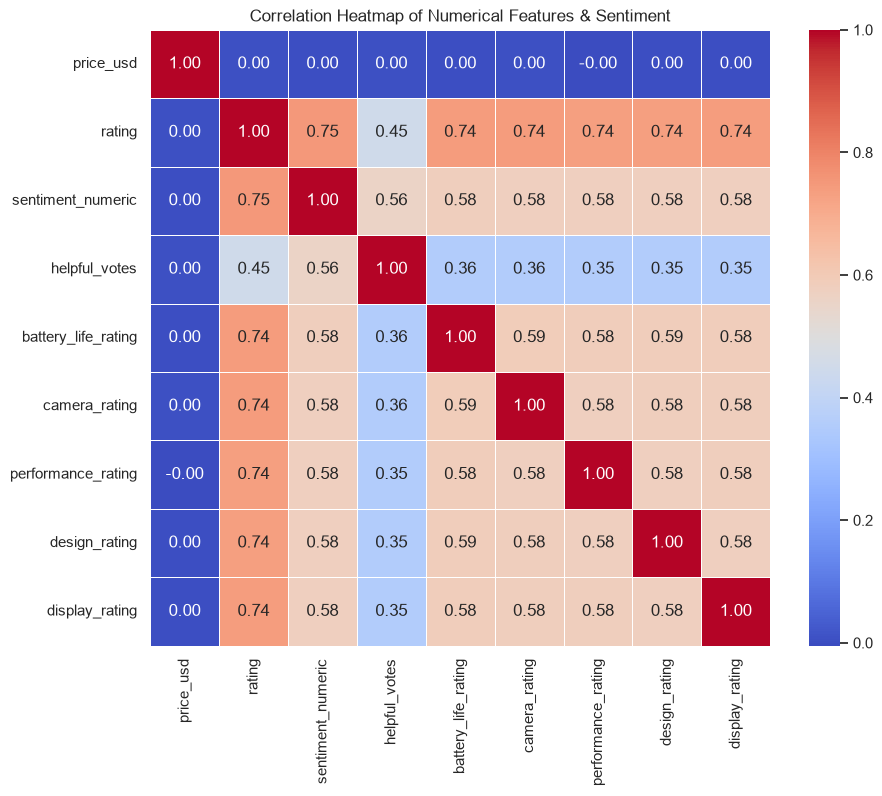

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map text sentiment to numerical values safely
sentiment_mapping = {'Negative': -1, 'Neutral': 0, 'Positive': 1}
# If your text is lowercase or uppercase, you can normalize it first:
data_df['sentiment_numeric'] = data_df['sentiment'].map(sentiment_mapping)

# 2. Define your numeric columns (using sentiment_numeric instead of sentiment)
numeric_cols = [
    'price_usd', 'rating', 'sentiment_numeric', 'helpful_votes',
    'battery_life_rating', 'camera_rating', 'performance_rating', 
    'design_rating', 'display_rating'
]

# 3. Generate the Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = data_df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features & Sentiment")
plt.show()

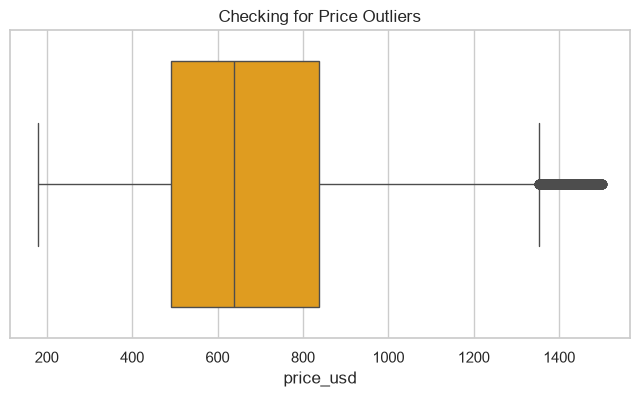

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=data_df['price_usd'], color="orange")
plt.title("Checking for Price Outliers")
plt.show()

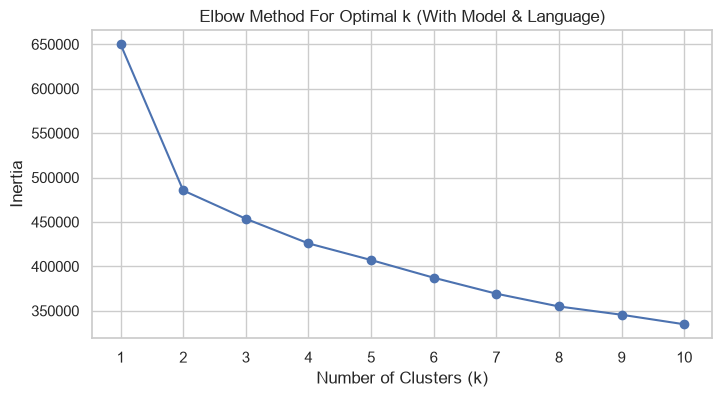

In [25]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Map sentiment text to numeric values safely
sentiment_mapping = {'Negative': -1, 'Neutral': 0, 'Positive': 1}
if 'sentiment' in data_df.columns and data_df['sentiment'].dtype == 'object':
    data_df['sentiment_numeric'] = data_df['sentiment'].map(sentiment_mapping).fillna(0)
else:
    data_df['sentiment_numeric'] = 0

# 2. Convert verified_purchase to numeric (1/0)
if 'verified_purchase' in data_df.columns:
    data_df['verified_numeric'] = data_df['verified_purchase'].astype(int)
else:
    data_df['verified_numeric'] = 0

# 3. Encode categorical columns (including brand, country, model, and language)
le_brand = LabelEncoder()
le_country = LabelEncoder()
le_model = LabelEncoder()
le_language = LabelEncoder()

data_df['brand_encoded'] = le_brand.fit_transform(data_df['brand'].astype(str))
data_df['country_encoded'] = le_country.fit_transform(data_df['country'].astype(str))
data_df['model_encoded'] = le_model.fit_transform(data_df['model'].astype(str))
data_df['language_encoded'] = le_language.fit_transform(data_df['language'].astype(str))

# 4. Define your EXPANDED feature set for clustering (with model and language added)
clustering_features = [
    'price_usd', 
    'rating', 
    'sentiment_numeric', 
    'helpful_votes',
    'verified_numeric', 
    'battery_life_rating', 
    'camera_rating', 
    'performance_rating', 
    'design_rating', 
    'display_rating', 
    'brand_encoded', 
    'country_encoded',
    'model_encoded',
    'language_encoded'
]

# Extract and scale the features
X = data_df[clustering_features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Run the Elbow Method with the updated features
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_scaled)
    inertia.append(kmeans_test.inertia_)

# 6. Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Method For Optimal k (With Model & Language)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [26]:
# Finalize K-Means Clustering with k=4 based on the Elbow Method
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
data_df['cluster'] = kmeans.fit_predict(X_scaled)

# Save your final dataset with the expanded feature clusters
data_df.to_csv("cleaned_smartphones.csv", index=False)
print("✅ Final K-Means model (k=4) successfully applied and saved to 'cleaned_smartphones.csv'!")

✅ Final K-Means model (k=4) successfully applied and saved to 'cleaned_smartphones.csv'!


In [27]:
data_df

,review_id,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,sentiment,country,...,design_rating,display_rating,helpful_votes,sentiment_numeric,verified_numeric,brand_encoded,country_encoded,model_encoded,language_encoded,cluster
0,1,Realme,Realme 12 Pro,337.310000,27996.73,INR,83.00,2.0,Negative,India,...,2,1,1,0,1,4,4,15,2,3
1,2,Realme,Realme 12 Pro,307.780702,1754.35,BRL,5.70,4.0,Positive,Brazil,...,3,2,5,0,1,4,1,15,3,0
2,3,Google,Pixel 6,864.530000,71755.99,INR,83.00,4.0,Positive,India,...,2,4,8,0,1,1,4,10,2,1
3,4,Xiaomi,Redmi Note 13,637.679739,923.58,AED,3.67,3.0,Positive,UAE,...,1,2,3,0,0,6,5,17,0,0
4,5,Motorola,Edge 50,792.129825,4515.14,BRL,5.70,3.0,Neutral,Brazil,...,2,1,0,0,1,2,1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,Realme,Realme 12 Pro,526.098039,804.93,AUD,1.53,4.0,Positive,Australia,...,3,5,4,0,0,4,0,15,0,2
49996,49997,Samsung,Galaxy Note 20,911.849673,1395.13,AUD,1.53,3.0,Neutral,Australia,...,1,3,2,0,0,5,0,2,0,0
49997,49998,Apple,iPhone SE,637.679739,923.58,AED,3.67,3.0,Positive,UAE,...,4,5,4,0,1,0,5,21,0,1
49998,49999,Realme,Realme Narzo 70,637.679739,923.58,USD,1.00,3.0,Positive,USA,...,1,3,6,0,1,4,7,16,0,0


In [28]:
#cluster profiling
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define expanded profiling columns (including verified purchases proportion)
profile_cols = [
    'price_usd', 
    'rating', 
    'sentiment_numeric', 
    'verified_numeric',  # Added: shows proportion of verified buyers (0 to 1)
    'battery_life_rating', 
    'camera_rating', 
    'performance_rating', 
    'helpful_votes'
]

# Calculate the mean for each cluster
cluster_summary = data_df.groupby('cluster')[profile_cols].mean()

# Add the total count of products/reviews in each cluster
cluster_summary['total_count'] = data_df['cluster'].value_counts().sort_index()

print("--- Expanded Cluster Profiling Summary Table ---")
display(cluster_summary)

--- Expanded Cluster Profiling Summary Table ---


,price_usd,rating,sentiment_numeric,verified_numeric,battery_life_rating,camera_rating,performance_rating,helpful_votes,total_count
cluster,,,,,,,,,
0,597.538612,3.177960,0.0,0.801112,2.646641,2.634275,2.653081,3.723255,13666
1,1022.130084,3.647715,0.0,0.792450,3.173773,3.205258,3.188140,4.251108,6543
2,611.328718,4.383139,0.0,0.801251,4.000924,3.994313,3.990901,5.093403,14068
3,675.075242,1.711442,0.0,0.805508,1.442473,1.444890,1.445017,2.026204,15723


C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\214018807.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_df, x='cluster', y='price_usd', palette="Set2")


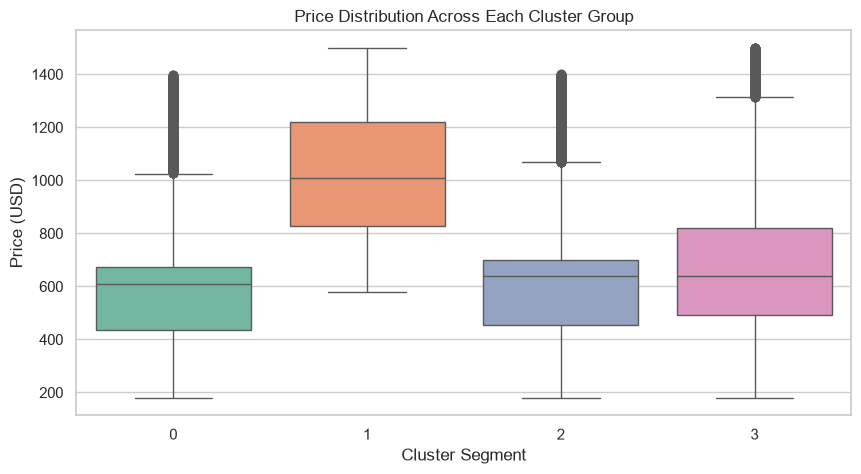

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\214018807.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_df, x='cluster', y='rating', palette="Set3")


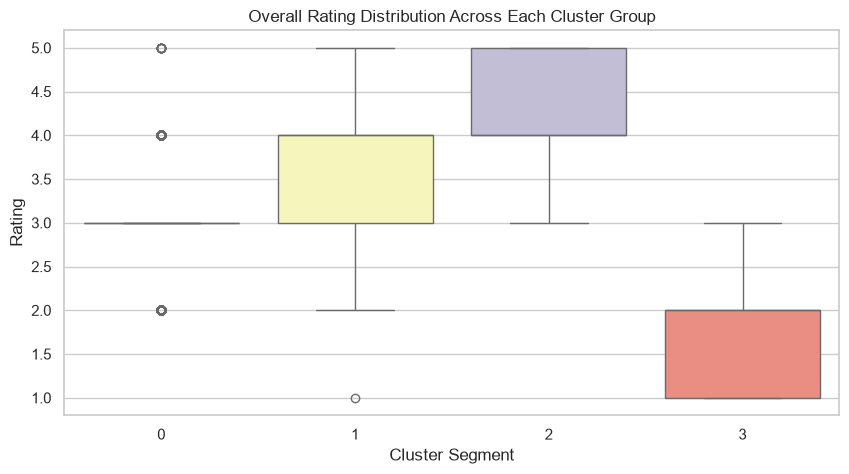

In [29]:
#Visualizing Price and Rating Differences Across Clusters
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Price Distribution by Cluster
plt.figure(figsize=(10, 5))
sns.boxplot(data=data_df, x='cluster', y='price_usd', palette="Set2")
plt.title("Price Distribution Across Each Cluster Group")
plt.xlabel("Cluster Segment")
plt.ylabel("Price (USD)")
plt.show()

# Rating Distribution by Cluster
plt.figure(figsize=(10, 5))
sns.boxplot(data=data_df, x='cluster', y='rating', palette="Set3")
plt.title("Overall Rating Distribution Across Each Cluster Group")
plt.xlabel("Cluster Segment")
plt.ylabel("Rating")
plt.show()

In [33]:
import pandas as pd

# Define cluster titles and exact summary descriptions
cluster_titles = {
    0: "Budget & Value Segment",
    1: "Premium Flagship Devices",
    2: "Mid-Range All-Rounders",
    3: "Niche & Specialized Options"
}

cluster_descriptions = {
    0: "Standard budget/value volume drivers ($597 average, baseline ratings).",
    1: "High-end luxury flagships ($1,022 average, dominant Apple presence).",
    2: "High-satisfaction mid-range devices ($611 average, maximum 4.38 rating).",
    3: "Problematic or low-performing models ($675 average, poor 1.71 rating)."
}

# Loop through each cluster to generate its top brands and summary
for cluster_id in sorted(data_df['cluster'].unique()):
    subset = data_df[data_df['cluster'] == cluster_id]
    cluster_name = cluster_titles.get(cluster_id, f"Cluster {cluster_id}")
    cluster_desc = cluster_descriptions.get(cluster_id, "")
    
    # Calculate metrics for deeper reasoning
    avg_price = subset['price_usd'].mean()
    avg_rating = subset['rating'].mean()
    avg_camera = subset['camera_rating'].mean()
    avg_performance = subset['performance_rating'].mean()
    
    print(f"\n==================================================")
    print(f"📌 CLUSTER {cluster_id}: {cluster_name}")
    print(f"==================================================")
    print(f"📝 Summary: {cluster_desc}\n")
    
    print(f"🏆 Top 3 Dominant Brands:")
    top_brands = subset['brand'].value_counts().head(3)
    for brand, count in top_brands.items():
        print(f"   - {brand}: {count} products")
        
    print(f"\n🔍 Detailed Specs & Reasoning:")
    print(f"   • Average Price: ${avg_price:.2f}")
    print(f"   • Overall Rating: {avg_rating:.2f} / 5.0")
    print(f"   • Performance Score: {avg_performance:.2f} | Camera Score: {avg_camera:.2f}")


📌 CLUSTER 0: Budget & Value Segment
📝 Summary: Standard budget/value volume drivers ($597 average, baseline ratings).

🏆 Top 3 Dominant Brands:
   - Xiaomi: 2671 products
   - Samsung: 2631 products
   - OnePlus: 2424 products

🔍 Detailed Specs & Reasoning:
   • Average Price: $597.54
   • Overall Rating: 3.18 / 5.0
   • Performance Score: 2.65 | Camera Score: 2.63

📌 CLUSTER 1: Premium Flagship Devices
📝 Summary: High-end luxury flagships ($1,022 average, dominant Apple presence).

🏆 Top 3 Dominant Brands:
   - Apple: 4932 products
   - Google: 1561 products
   - Motorola: 48 products

🔍 Detailed Specs & Reasoning:
   • Average Price: $1022.13
   • Overall Rating: 3.65 / 5.0
   • Performance Score: 3.19 | Camera Score: 3.21

📌 CLUSTER 2: Mid-Range All-Rounders
📝 Summary: High-satisfaction mid-range devices ($611 average, maximum 4.38 rating).

🏆 Top 3 Dominant Brands:
   - Realme: 2501 products
   - OnePlus: 2444 products
   - Xiaomi: 2400 products

🔍 Detailed Specs & Reasoning:
   •

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\1627572059.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.index, y=top_brands.values, palette="Blues_r" if cluster_id==0 else "Purples_r")


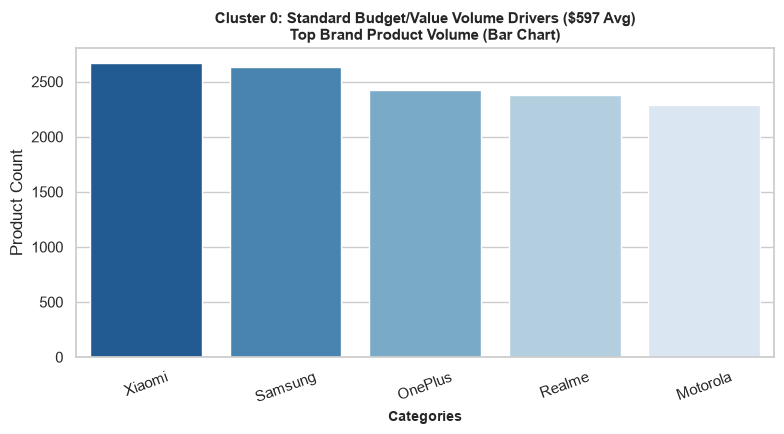

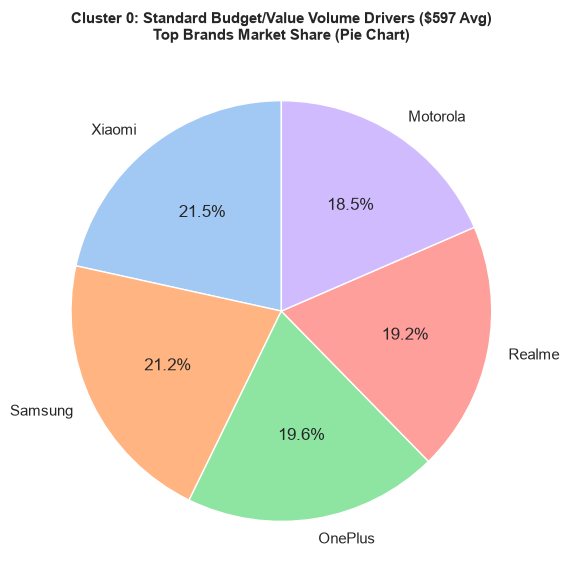

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\1627572059.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.index, y=top_brands.values, palette="Blues_r" if cluster_id==0 else "Purples_r")


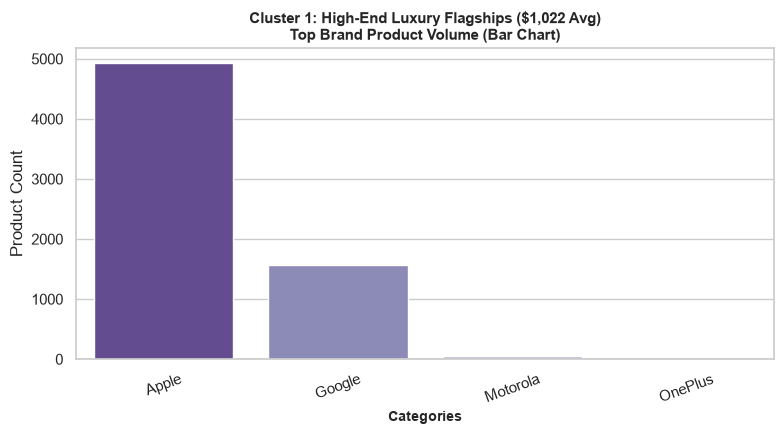

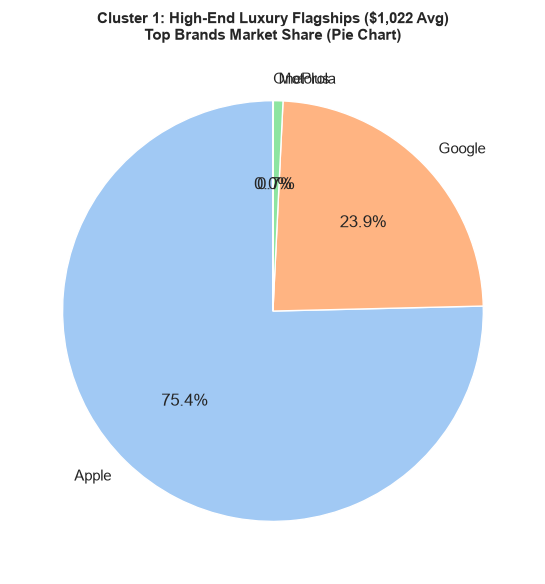

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\1627572059.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metric_names, y=avg_scores, palette=palette_choice)


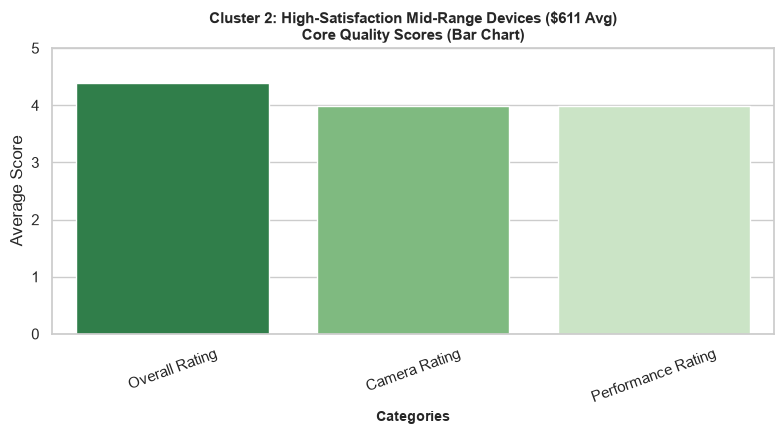

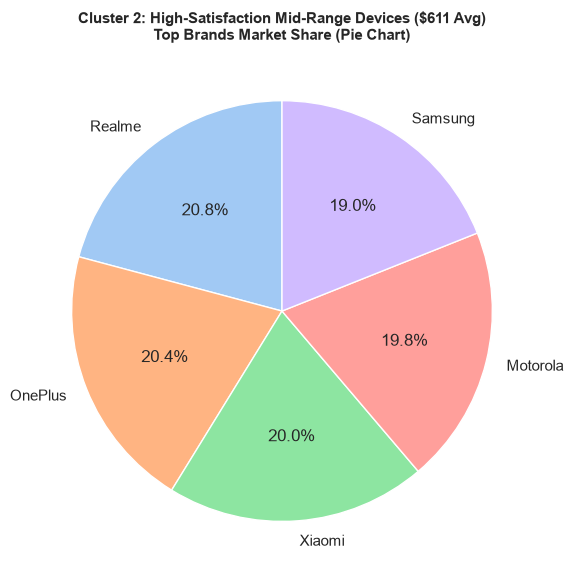

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_14492\1627572059.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metric_names, y=avg_scores, palette=palette_choice)


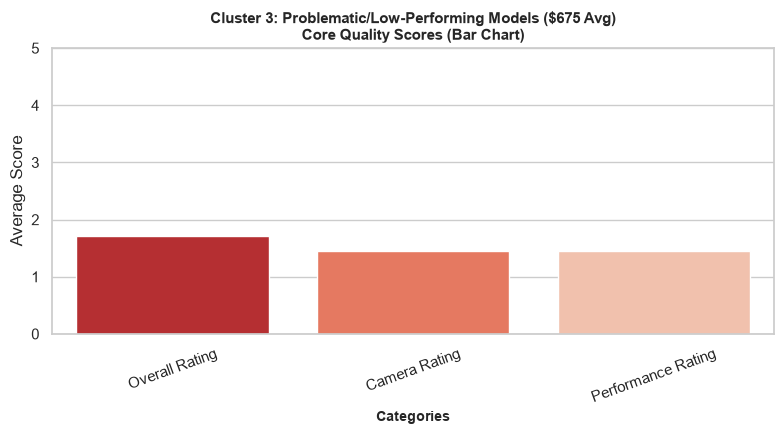

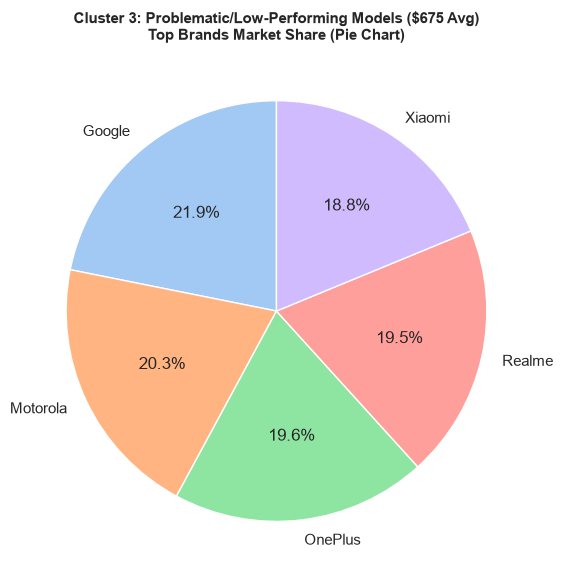

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_titles = {
    0: "Cluster 0: Standard Budget/Value Volume Drivers ($597 Avg)",
    1: "Cluster 1: High-End Luxury Flagships ($1,022 Avg)",
    2: "Cluster 2: High-Satisfaction Mid-Range Devices ($611 Avg)",
    3: "Cluster 3: Problematic/Low-Performing Models ($675 Avg)"
}

sns.set_theme(style="whitegrid")

# Loop through each cluster to generate individual bar and pie charts
for cluster_id in sorted(data_df['cluster'].unique()):
    subset = data_df[data_df['cluster'] == cluster_id]
    title = cluster_titles.get(cluster_id)
    top_brands = subset['brand'].value_counts().head(5)
    
    # -------------------------------------------------------------
    # 1. BAR CHART: Top Brands Volume or Quality Scores
    # -------------------------------------------------------------
    plt.figure(figsize=(8, 4.5))
    if cluster_id in [0, 1]:
        sns.barplot(x=top_brands.index, y=top_brands.values, palette="Blues_r" if cluster_id==0 else "Purples_r")
        plt.title(f"{title}\nTop Brand Product Volume (Bar Chart)", fontsize=11, fontweight='bold')
        plt.ylabel("Product Count")
    else:
        metrics = ['rating', 'camera_rating', 'performance_rating']
        metric_names = ['Overall Rating', 'Camera Rating', 'Performance Rating']
        avg_scores = [subset[m].mean() for m in metrics]
        palette_choice = "Greens_r" if cluster_id == 2 else "Reds_r"
        sns.barplot(x=metric_names, y=avg_scores, palette=palette_choice)
        plt.title(f"{title}\nCore Quality Scores (Bar Chart)", fontsize=11, fontweight='bold')
        plt.ylabel("Average Score")
        plt.ylim(0, 5)
        
    plt.xlabel("Categories", fontsize=10, fontweight='bold')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    
    # -------------------------------------------------------------
    # 2. PIE CHART: Brand Market Share Breakdown
    # -------------------------------------------------------------
    plt.figure(figsize=(6, 6))
    plt.pie(
        top_brands.values, 
        labels=top_brands.index, 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=sns.color_palette("pastel")
    )
    plt.title(f"{title}\nTop Brands Market Share (Pie Chart)", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()